In [1]:
!pip install langchain langchain_core langchain_community langgraph langchain_openai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 46.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 43.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 591.1/591.1 kB 17.7 MB/s  0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
  Attempting uninstall: langchain-protocol
    Found existing installation: langchain-protocol 0.0.20
    Uninstalling langchain-protocol-0.0.20:
      Successfully uninstalled langchain-protocol-0.0.20
  Attempting uninstall: langchain_core
    Found existing installation: langchain-core 1.7.4
    Uninstalling langchain-core-1.7.4:
      Successfully uninstalled langchain-core-1.7.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [langchain_community]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following d

In [2]:
from google.colab import userdata
import os
os.environ['OPENAI_API_KEY'] = userdata.get('openAiKey')

In [3]:
from langchain_openai import ChatOpenAI
llm = ChatOpenAI(
    model="gpt-4o-mini",
    temperature=0
)
print("AI Model Initialized Successfully")

AI Model Initialized Successfully


In [8]:
response = llm.invoke("Explain what an HR recruitment agent does in two sentences.")

print(response.content)

An HR recruitment agent is responsible for sourcing, screening, and selecting candidates for job openings within an organization, ensuring that the best talent is matched to the company's needs. They also collaborate with hiring managers to understand job requirements, conduct interviews, and facilitate the hiring process from start to finish.


In [11]:
from typing import TypedDict, Optional
from langgraph.graph import StateGraph, START, END

# Define the State structure
class State(TypedDict):
    application: str
    experience_level: Optional[str]
    skill_match: Optional[str]
    response: Optional[str]

# Initialize the workflow graph with the State definition
workflow = StateGraph(State)

In [6]:
from langchain_core.prompts import ChatPromptTemplate

In [12]:
def categorize_experience(state: State) -> State:
  print("\nCategorizing the experience level of candidate : ")
  prompt = ChatPromptTemplate.from_template(
      "Based on the following job application, categorize the candidate as 'Entry-level', 'Mid-level' or 'Senior-level'"
      "Application : {application}"
  )
  chain = prompt | llm
  experience_level = chain.invoke({"application": state["application"]}).content
  print(f"Experience Level : {experience_level}")
  return {"experience_level" : experience_level}

def assess_skillset(state: State) -> State:
  print("\nAssessing the skillset of candidate : ")
  prompt = ChatPromptTemplate.from_template(
      "Based on the job application for a Python Developer, assess the candidate's skillset"
      "Respond with either 'Match' or 'No Match'"
      "Application : {application}"
  )
  chain = prompt | llm
  skill_match = chain.invoke({"application": state["application"]}).content
  print(f"Skill Match : {skill_match}")
  return {"skill_match" : skill_match}

def schedule_hr_interview(state: State) -> State:
  print("\nScheduling the interview : ")
  return {"response" : "Candidate has been shortlisted for an HR interview."}

def escalate_to_recruiter(state: State) -> State:
  print("Escalating to recruiter")
  return {"response" : "Candidate has senior-level experience but doesn't match job skills."}

def reject_application(state: State) -> State:
  print("Sending rejecting email")
  return {"response" : "Candidate doesn't meet JD and has been rejected."}

In [13]:
workflow.add_node("categorize_experience", categorize_experience)
workflow.add_node("assess_skillset", assess_skillset)
workflow.add_node("schedule_hr_interview", schedule_hr_interview)
workflow.add_node("escalate_to_recruiter", escalate_to_recruiter)
workflow.add_node("reject_application", reject_application)

In [14]:
def route_app(state: State) -> str:
  if(state["skill_match"] == "Match"):
    return "schedule_hr_interview"
  elif(state["experience_level"] == "Senior-level"):
    return "escalate_to_recruiter"
  else:
    return "reject_application"

In [19]:
try:
    # Connect the start of the workflow to the first node
    workflow.add_edge(START, "categorize_experience")
    workflow.add_edge("categorize_experience", "assess_skillset")
    workflow.add_conditional_edges("assess_skillset", route_app)
    print("Edges added successfully.")
except ValueError as e:
    print(f"Edges already configured or modified: {e}")

Edges already configured or modified: Branch with name `route_app` already exists for node `assess_skillset`


In [20]:
workflow.add_edge(START, "categorize_experience")
workflow.add_edge("assess_skillset", END)
workflow.add_edge("escalate_to_recruiter", END)
workflow.add_edge("reject_application", END)
workflow.add_edge("schedule_hr_interview", END)

In [21]:
app = workflow.compile()

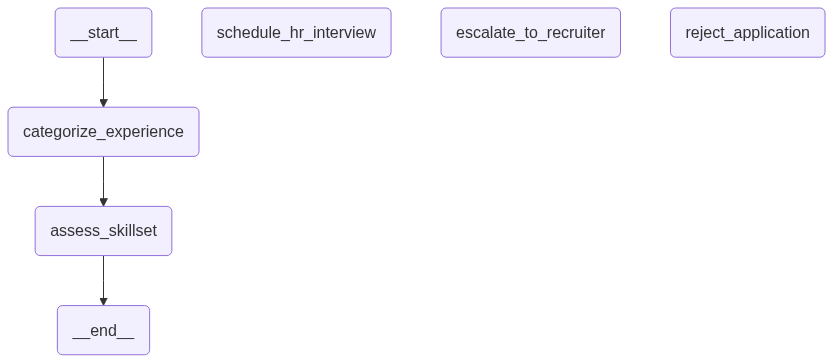

In [22]:
from IPython.display import Image, display

display(
    Image(
        app.get_graph().draw_mermaid_png()
    )
)

In [23]:
# 1. Re-initialize the workflow to clear any bad edges/states
workflow = StateGraph(State)

# 2. Add all nodes
workflow.add_node("categorize_experience", categorize_experience)
workflow.add_node("assess_skillset", assess_skillset)
workflow.add_node("schedule_hr_interview", schedule_hr_interview)
workflow.add_node("escalate_to_recruiter", escalate_to_recruiter)
workflow.add_node("reject_application", reject_application)

# 3. Add edges and conditional routing
workflow.add_edge(START, "categorize_experience")
workflow.add_edge("categorize_experience", "assess_skillset")

# The conditional routing dictates which node to go to next based on route_app output
workflow.add_conditional_edges(
    "assess_skillset",
    route_app,
    {
        "schedule_hr_interview": "schedule_hr_interview",
        "escalate_to_recruiter": "escalate_to_recruiter",
        "reject_application": "reject_application"
    }
)

# 4. Once an outcome node is executed, routing ends
workflow.add_edge("schedule_hr_interview", END)
workflow.add_edge("escalate_to_recruiter", END)
workflow.add_edge("reject_application", END)

# 5. Compile the corrected graph
app = workflow.compile()
print("Graph compiled successfully!")

Graph compiled successfully!


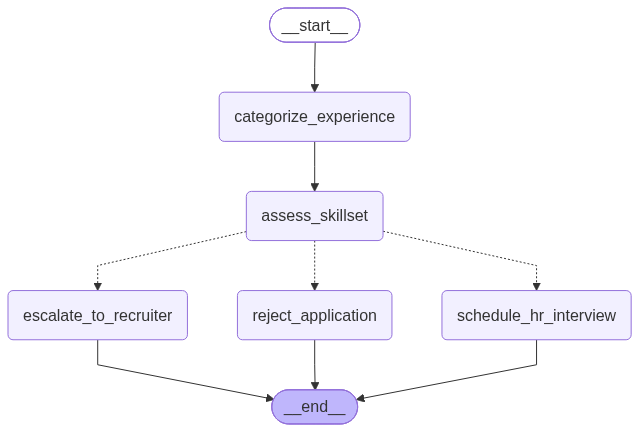

In [24]:
# Visualize the corrected graph structure
from IPython.display import Image, display

display(
    Image(
        app.get_graph().draw_mermaid_png()
    )
)

In [26]:
def run_candidate_screening(application: str):
  results = app.invoke({"application" : application})
  return {
      "experience_level" : results["experience_level"],
      "skill_match" : results["skill_match"],
      "response" : results["response"]
  }

In [27]:
application_text = "I have 10 years of experience in software engineering with expertise in JAVA"
results = run_candidate_screening(application_text)
print("\n\nComputed Results :")
print(f"Application: {application_text}")
print(f"Experience Level: {results['experience_level']}")
print(f"Skill Match: {results['skill_match']}")
print(f"Response: {results['response']}")


Categorizing the experience level of candidate : 
Experience Level : Based on the information provided in the job application, the candidate would be categorized as 'Senior-level'. With 10 years of experience in software engineering, they possess a significant amount of expertise and likely have advanced skills and knowledge in their field.

Assessing the skillset of candidate : 
Skill Match : No Match
Sending rejecting email


Computed Results :
Application: I have 10 years of experience in software engineering with expertise in JAVA
Experience Level: Based on the information provided in the job application, the candidate would be categorized as 'Senior-level'. With 10 years of experience in software engineering, they possess a significant amount of expertise and likely have advanced skills and knowledge in their field.
Skill Match: No Match
Response: Candidate doesn't meet JD and has been rejected.


In [28]:
application_text = "I have 10 years of experience in software engineering with expertise in Python"
results = run_candidate_screening(application_text)
print("\n\nComputed Results :")
print(f"Application: {application_text}")
print(f"Experience Level: {results['experience_level']}")
print(f"Skill Match: {results['skill_match']}")
print(f"Response: {results['response']}")


Categorizing the experience level of candidate : 
Experience Level : Based on the information provided in the job application, the candidate would be categorized as 'Senior-level'. Having 10 years of experience in software engineering indicates a significant level of expertise and likely involvement in complex projects, leadership roles, or specialized skills.

Assessing the skillset of candidate : 
Skill Match : Match

Scheduling the interview : 


Computed Results :
Application: I have 10 years of experience in software engineering with expertise in Python
Experience Level: Based on the information provided in the job application, the candidate would be categorized as 'Senior-level'. Having 10 years of experience in software engineering indicates a significant level of expertise and likely involvement in complex projects, leadership roles, or specialized skills.
Skill Match: Match
Response: Candidate has been shortlisted for an HR interview.
